#Drive Mount + Paths

In [1]:
from google.colab import drive
drive.mount('/content/drive')

#Project folder in Drive
BASE = "/content/drive/MyDrive/CourseWork/CSV_Files"

import os
DATA_DIR = BASE
OUT_DIR  = f"{BASE}/Cleaned_Output"
os.makedirs(OUT_DIR, exist_ok=True)

# Input file name
BUSINESS_FILE = "yelp_academic_dataset_business.csv"
IN_PATH = f"{DATA_DIR}/{BUSINESS_FILE}"

print("IN_PATH:", IN_PATH)
print("OUT_DIR:", OUT_DIR)


Mounted at /content/drive
IN_PATH: /content/drive/MyDrive/CourseWork/CSV_Files/yelp_academic_dataset_business.csv
OUT_DIR: /content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output


#Environmental Setup + Spark Session

In [2]:
import os, subprocess

def sh(cmd):
    return subprocess.run(cmd, shell=True, check=True,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT).stdout.decode()

# Java + PySpark
sh("apt-get -y update >/dev/null")
sh("apt-get -y install openjdk-17-jdk-headless >/dev/null")
sh("pip -q uninstall -y pyspark findspark || true")
sh("pip -q install -U pyspark==4.0.1 pyarrow pandas matplotlib >/dev/null")

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

local_dir = "/content/spark_tmp"
warehouse_dir = "/content/spark_warehouse"
os.makedirs(local_dir, exist_ok=True)
os.makedirs(warehouse_dir, exist_ok=True)

spark = (SparkSession.builder
         .appName("Yelp_Business_Cleaning_And_Dashboard")
         .master("local[*]")
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.driver.memory", "2g")
         .config("spark.local.dir", local_dir)
         .config("spark.sql.warehouse.dir", warehouse_dir)
         .getOrCreate())

spark.sparkContext.setLogLevel("WARN")
print("Spark Version:", spark.version)


Spark Version: 4.0.1


#Data Loading

In [3]:
df_B1 = (spark.read
         .option("header", "true")
         .option("inferSchema", "true")
         .option("multiLine", "true")
         .option("escape", "\"")
         .option("quote", "\"")
         .csv(IN_PATH))

print("Loaded yelp_academic_dataaset_business.csv")
print("Columns:", df_B1.columns)
df_B1.printSchema()
df_B1.show(10, truncate=90)

Loaded yelp_academic_dataaset_business.csv
Columns: ['address', 'attributes', 'business_id', 'categories', 'city', 'hours', 'is_open', 'latitude', 'longitude', 'name', 'postal_code', 'review_count', 'stars', 'state']
root
 |-- address: string (nullable = true)
 |-- attributes: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- categories: string (nullable = true)
 |-- city: string (nullable = true)
 |-- hours: string (nullable = true)
 |-- is_open: integer (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- name: string (nullable = true)
 |-- postal_code: string (nullable = true)
 |-- review_count: integer (nullable = true)
 |-- stars: double (nullable = true)
 |-- state: string (nullable = true)

+------------------------------------------+------------------------------------------------------------------------------------------+----------------------+-------------------------------------------------------------

#Data Cleaning

##Cleaning + Standarization

In [4]:
# 1.1 Normalize column names
df_B2 = df_B1.toDF(*[c.strip().lower().replace(" ", "_") for c in df_B1.columns])

def rename_first_startswith(df_in, prefix, new_name):
    cand = [c for c in df_in.columns if c.startswith(prefix)]
    if cand and new_name not in df_in.columns:
        return df_in.withColumnRenamed(cand[0], new_name)
    return df_in

df_B2 = rename_first_startswith(df_B2, "review", "review_count")
df_B2 = rename_first_startswith(df_B2, "postal", "postal_code")

# 1.2 Enforce key integrity + deduplicate
df_B3 = (df_B2
         .dropna(subset=["business_id"])
         .dropDuplicates(["business_id"]))

# 1.3 Trim text fields (stability for grouping/labels)
for c in ["name", "address", "city", "state", "postal_code", "categories"]:
    if c in df_B3.columns:
        df_B3 = df_B3.withColumn(c, F.trim(F.col(c)))

# 1.4 State standardization + postal_code cleanup
if "state" in df_B3.columns:
    df_B3 = df_B3.withColumn("state", F.upper(F.col("state")))

if "postal_code" in df_B3.columns:
    df_B3 = df_B3.withColumn("postal_code", F.regexp_extract(F.col("postal_code"), r"(\d{5})", 1))

# 1.5 Cast key numeric fields
cast_map = {
    "latitude": "double",
    "longitude": "double",
    "stars": "double",
    "review_count": "int",
    "is_open": "int"
}
for c, t in cast_map.items():
    if c in df_B3.columns:
        df_B3 = df_B3.withColumn(c, F.col(c).cast(t))

# 1.6 Neat geo formatting (consistent decimals)
DECIMALS = 5
if "latitude" in df_B3.columns:
    df_B3 = df_B3.withColumn("latitude", F.round(F.col("latitude"), DECIMALS))
if "longitude" in df_B3.columns:
    df_B3 = df_B3.withColumn("longitude", F.round(F.col("longitude"), DECIMALS))

# 1.7 Minimal imputations for dashboard robustness
if "is_open" in df_B3.columns:
    df_B3 = df_B3.withColumn("is_open", F.coalesce(F.col("is_open"), F.lit(0)).cast("int"))

if "review_count" in df_B3.columns:
    df_B3 = df_B3.withColumn("review_count", F.coalesce(F.col("review_count"), F.lit(0)).cast("int"))

for c in ["city", "state"]:
    if c in df_B3.columns:
        df_B3 = df_B3.withColumn(
            c,
            F.when(F.col(c).isNull() | (F.length(F.col(c)) == 0), F.lit("UNKNOWN")).otherwise(F.col(c))
        )

# 1.8 Domain rules: stars and valid geo bounds
if "stars" in df_B3.columns:
    df_B3 = df_B3.withColumn(
        "stars",
        F.when(F.col("stars").isNull(), F.lit(None))
         .when(F.col("stars") < 1, F.lit(1.0))
         .when(F.col("stars") > 5, F.lit(5.0))
         .otherwise(F.col("stars"))
    )

if "latitude" in df_B3.columns:
    df_B3 = df_B3.filter(F.col("latitude").isNull() | ((F.col("latitude") >= -90) & (F.col("latitude") <= 90)))
if "longitude" in df_B3.columns:
    df_B3 = df_B3.filter(F.col("longitude").isNull() | ((F.col("longitude") >= -180) & (F.col("longitude") <= 180)))

df_B3 = df_B3.cache()

print("Cleaning complete (df_B3). Sample:")
df_B3.show(10, truncate=90)


Cleaning complete (df_B3). Sample:
+--------------------------+------------------------------------------------------------------------------------------+----------------------+----------------------------------------------------------------------------------------+-----------+---------------------------------------------------------------------------------+-------+--------+----------+------------------------------------------+-----------+------------+-----+-----+
|                   address|                                                                                attributes|           business_id|                                                                              categories|       city|                                                                            hours|is_open|latitude| longitude|                                      name|postal_code|review_count|stars|state|
+--------------------------+---------------------------------------------------------------------

##Feature Extraction + Outlier + Winsorization

In [5]:
df_B4 = df_B3

if "attributes" in df_B4.columns:
    dtype = dict(df_B4.dtypes).get("attributes", "")
    if dtype == "string":
        df_B4 = df_B4.withColumn(
            "attributes_json",
            F.when(F.col("attributes").isNull() | (F.upper(F.col("attributes")) == F.lit("NULL")), F.lit(None))
             .otherwise(F.col("attributes"))
        )
    else:
        df_B4 = df_B4.withColumn("attributes_json", F.to_json(F.col("attributes")))

    df_B4 = df_B4.drop("attributes")

    price_raw = F.coalesce(
        F.get_json_object(F.col("attributes_json"), "$.RestaurantsPriceRange2"),
        F.get_json_object(F.col("attributes_json"), "$.restaurantspricerange2")
    )

    df_B4 = df_B4.withColumn("price_range", price_raw.cast("int"))

    df_B4 = df_B4.withColumn(
        "price_range_label",
        F.when(F.col("price_range").isNull(), F.lit("Unknown"))
         .when(F.col("price_range") == 1, F.lit("1"))
         .when(F.col("price_range") == 2, F.lit("2"))
         .when(F.col("price_range") == 3, F.lit("3"))
         .when(F.col("price_range") == 4, F.lit("4"))
         .otherwise(F.lit("Unknown"))
    )

    df_B4 = df_B4.drop("attributes_json")
else:
    df_B4 = df_B4.withColumn("price_range", F.lit(None).cast("int"))
    df_B4 = df_B4.withColumn("price_range_label", F.lit("Unknown"))

# Section :3 Outlier flag + winsorization (review_count) using IQR

def winsorize_iqr(df_in, colname, k=1.5, rel_err=0.01):
    q1, q3 = (df_in.select(colname)
              .where(F.col(colname).isNotNull())
              .approxQuantile(colname, [0.25, 0.75], rel_err))
    iqr = q3 - q1
    lower = q1 - k * iqr
    upper = q3 + k * iqr

    return (df_in
        .withColumn(
            f"{colname}_outlier_flag",
            F.when(F.col(colname).isNull(), F.lit(0))
             .when((F.col(colname) < lower) | (F.col(colname) > upper), F.lit(1))
             .otherwise(F.lit(0))
        )
        .withColumn(
            colname,
            F.when(F.col(colname).isNull(), F.lit(None))
             .when(F.col(colname) < lower, F.lit(lower))
             .when(F.col(colname) > upper, F.lit(upper))
             .otherwise(F.col(colname))
        )
    )

df_B5 = winsorize_iqr(df_B4, "review_count", k=1.5).withColumn("review_count", F.col("review_count").cast("int"))

# Section 4: Primary category (fast parsing)

if "categories" in df_B5.columns:
    df_B5 = df_B5.withColumn(
        "primary_category",
        F.when(F.col("categories").isNull(), F.lit("UNKNOWN"))
         .otherwise(F.trim(F.split(F.col("categories"), ",")[0]))
    )
else:
    df_B5 = df_B5.withColumn("primary_category", F.lit("UNKNOWN"))

print("Feature Extraction, Outlier Flag + Winsorization complete. Sample:")
df_B5.select("price_range_label", "review_count", "review_count_outlier_flag", "primary_category").show(10, truncate=70)


Feature Extraction, Outlier Flag + Winsorization complete. Sample:
+-----------------+------------+-------------------------+----------------+
|price_range_label|review_count|review_count_outlier_flag|primary_category|
+-----------------+------------+-------------------------+----------------+
|          Unknown|           8|                        0|     Hair Salons|
|          Unknown|           8|                        0|  Organic Stores|
|          Unknown|          12|                        0|            Food|
|          Unknown|          78|                        1|     Restaurants|
|          Unknown|          78|                        1|            Food|
|          Unknown|          78|                        1|        Caterers|
|          Unknown|          11|                        0|     Restaurants|
|          Unknown|           5|                        0|    Electricians|
|          Unknown|          78|                        1|            Food|
|          Unknown|  

In [6]:
df_B5_clean = df_B5.select(
    "business_id",
    "city",
    "state",
    "latitude",
    "longitude",
    "stars",
    "review_count",
    "is_open",
    "primary_category",
    "review_count_outlier_flag"
)

df_B5_clean.coalesce(1).write \
    .option("header", "true") \
    .option("quote", '"') \
    .option("escape", '"') \
    .option("multiLine", "true") \
    .csv("business_tableau_clean")


#Saving Cleaned Dataset

In [7]:
import glob, shutil

# Keep ONLY dashboard-required columns
final_cols = [
    "business_id", "name", "city", "state",
    "latitude", "longitude",
    "stars", "review_count", "is_open",
    "primary_category", "price_range_label",
    "review_count_outlier_flag"
]
final_cols = [c for c in final_cols if c in df_B5.columns]

df_B6 = df_B5.select(final_cols)

print("Final dashboard dataset columns:", df_B6.columns)

def save_single_csv(df_in, out_dir, base_name="Cleaned_business", coalesce_n=1):
    tmp_dir = os.path.join(out_dir, f"_tmp_{base_name}")
    final_csv = os.path.join(out_dir, f"{base_name}.csv")

    (df_in.coalesce(int(coalesce_n))
         .write.mode("overwrite")
         .option("header", True)
         .csv(tmp_dir))

    part_files = sorted(glob.glob(os.path.join(tmp_dir, "part-*.csv")))
    if not part_files:
        raise FileNotFoundError("No part-*.csv found in temp output folder.")

    shutil.move(part_files[0], final_csv)
    shutil.rmtree(tmp_dir, ignore_errors=True)

    print("Saved:", final_csv)
    print("Deleted temp folder:", tmp_dir)
    return final_csv

CLEANED_PATH = save_single_csv(df_B6, OUT_DIR, base_name="Cleaned_business", coalesce_n=1)


Final dashboard dataset columns: ['business_id', 'name', 'city', 'state', 'latitude', 'longitude', 'stars', 'review_count', 'is_open', 'primary_category', 'price_range_label', 'review_count_outlier_flag']
Saved: /content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output/Cleaned_business.csv
Deleted temp folder: /content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output/_tmp_Cleaned_business


In [ ]:
df_B6.show(10, truncate=False)


+----------------------+------------------------------------------+-----------+-----+--------+----------+-----+------------+-------+----------------+-----------------+-------------------------+
|business_id           |name                                      |city       |state|latitude|longitude |stars|review_count|is_open|primary_category|price_range_label|review_count_outlier_flag|
+----------------------+------------------------------------------+-----------+-----+--------+----------+-----+------------+-------+----------------+-----------------+-------------------------+
|--LC8cIrALInl2vyo701tg|Studio G Salon                            |Tampa      |FL   |28.06589|-82.5593  |5.0  |8           |1      |Hair Salons     |Unknown          |0                        |
|--rS-rnOIZxoiDA8yctWpQ|Publix GreenWise Market                   |Tampa      |FL   |27.94329|-82.45016 |5.0  |8           |1      |Organic Stores  |Unknown          |0                        |
|--zb12mw2YK-7j6UaHzm8w|Billy 

#Descriptive Analysis

##Helper: Descriptive Measures Table Function

In [8]:
# DESCRIPTIVE MEASURES

def numeric_desc_table(df_in, col, mode_bin=None, rel_err=0.01):
    """
    Returns 1-row Spark table:
    n, mean, median, mode (exact OR binned), min, max, range, variance, stddev, q1, q3, IQR, skewness
    """
    dfv = df_in.select(col).where(F.col(col).isNotNull())

    q1, med, q3 = dfv.approxQuantile(col, [0.25, 0.5, 0.75], rel_err)
    iqr = q3 - q1

    agg = (dfv.agg(
        F.count(col).alias("n"),
        F.mean(col).alias("mean"),
        F.min(col).alias("min"),
        F.max(col).alias("max"),
        F.variance(col).alias("variance"),
        F.stddev(col).alias("stddev"),
        F.skewness(col).alias("skewness")
    ).collect()[0].asDict())

    data_range = (agg["max"] - agg["min"]) if (agg["min"] is not None and agg["max"] is not None) else None

    # Mode (exact or binned)
    if mode_bin is None:
        mode_row = (dfv.groupBy(col).count()
                    .orderBy(F.desc("count"), F.asc(col))
                    .limit(1).collect())
        mode_val = mode_row[0][col] if mode_row else None
        mode_cnt = mode_row[0]["count"] if mode_row else None
        mode_key = "mode_exact"
    else:
        bin_col = "mode_bin_bucket"
        binned = dfv.withColumn(bin_col, (F.floor(F.col(col)/F.lit(mode_bin))*F.lit(mode_bin)).cast("int"))
        mode_row = (binned.groupBy(bin_col).count()
                    .orderBy(F.desc("count"), F.asc(bin_col))
                    .limit(1).collect())
        mode_val = mode_row[0][bin_col] if mode_row else None
        mode_cnt = mode_row[0]["count"] if mode_row else None
        mode_key = f"mode_bin_start_{mode_bin}"

    return spark.createDataFrame([{
        "variable": col,
        "n": int(agg["n"]) if agg["n"] is not None else None,
        "mean": float(agg["mean"]) if agg["mean"] is not None else None,
        "median": float(med) if med is not None else None,
        mode_key: mode_val,
        "mode_count": int(mode_cnt) if mode_cnt is not None else None,
        "min": float(agg["min"]) if agg["min"] is not None else None,
        "max": float(agg["max"]) if agg["max"] is not None else None,
        "range": float(data_range) if data_range is not None else None,
        "variance": float(agg["variance"]) if agg["variance"] is not None else None,
        "stddev": float(agg["stddev"]) if agg["stddev"] is not None else None,
        "q1": float(q1) if q1 is not None else None,
        "q3": float(q3) if q3 is not None else None,
        "IQR": float(iqr) if iqr is not None else None,
        "skewness": float(agg["skewness"]) if agg["skewness"] is not None else None
    }])


##KPI Table

In [9]:
print("\n---------- Dashboard KPIs ----------")

# Cache dataset for repeated dashboard operations
df_B7 = df_B6.cache()

# Calculate KPIs
df_kpis_B = df_B7.agg(
    F.countDistinct("business_id").alias("Total Businesses"),
    F.round(F.avg("is_open") * 100, 2).alias("Open Rate (%)"),
    F.round(F.avg("stars"), 2).alias("Average Stars"),
    F.round(F.avg("review_count"), 2).alias("Average Review Count")
)

# Display KPI table
df_kpis_B.show(truncate=False)



---------- Dashboard KPIs ----------
+----------------+-------------+-------------+--------------------+
|Total Businesses|Open Rate (%)|Average Stars|Average Review Count|
+----------------+-------------+-------------+--------------------+
|150346          |79.62        |3.6          |26.43               |
+----------------+-------------+-------------+--------------------+



##Dashboard Charts

### Chart 01 - Map Density (Latitude/Longitude)


---------- CHART 01: Business Locations (Density) ----------

Descriptive Measures: Latitude (degrees)
+-------+-------+------------------+--------+--------+----------+----------+------+--------+--------+------------------+-------------------+------------------+--------+-----------------+
|IQR    |max    |mean              |median  |min     |mode_count|mode_exact|n     |q1      |q3      |range             |skewness           |stddev            |variable|variance         |
+-------+-------+------------------+--------+--------+----------+----------+------+--------+--------+------------------+-------------------+------------------+--------+-----------------+
|7.78237|53.6792|36.671150187567356|38.74682|27.55513|148       |34.42033  |150346|32.16994|39.95231|26.124070000000003|0.30477153016230635|5.8727589151732555|latitude|34.48929727574696|
+-------+-------+------------------+--------+--------+----------+----------+------+--------+--------+------------------+-------------------+--------

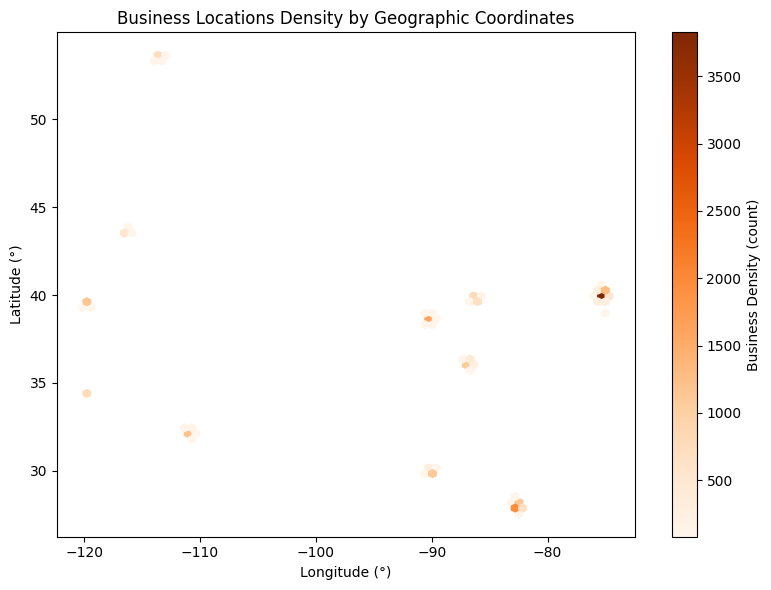

In [ ]:
import matplotlib.pyplot as plt

print("\n---------- CHART 01: Business Locations (Density) ----------")

print("\nDescriptive Measures: Latitude (degrees)")
numeric_desc_table(
    df_B7.where(F.col("latitude").isNotNull()),
    "latitude"
).show(truncate=False)

print("\nDescriptive Measures: Longitude (degrees)")
numeric_desc_table(
    df_B7.where(F.col("longitude").isNotNull()),
    "longitude"
).show(truncate=False)

map_pd = (
    df_B7
    .select("longitude", "latitude")
    .where(
        F.col("latitude").isNotNull() &
        F.col("longitude").isNotNull()
    )
    .sample(False, 0.15, seed=15)
    .limit(200000)
    .toPandas()
)

plt.figure(figsize=(8, 6))

hb = plt.hexbin(
    map_pd["longitude"],
    map_pd["latitude"],
    gridsize=70,
    cmap="Oranges",
    mincnt=1,
    vmin=80
)

plt.colorbar(hb, label="Business Density (count)")
plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.title("Business Locations Density by Geographic Coordinates")
plt.grid(False)
plt.tight_layout()
plt.show()



### Chart 02 - Top 20 Cities by Business Count


--------- CHART 02: Top 20 Cities by Business Count ---------

Supporting Frequency Table (Top 20 Cities)
+----------------+-----+--------------+
|city            |state|business_count|
+----------------+-----+--------------+
|Philadelphia    |PA   |14568         |
|Tucson          |AZ   |9251          |
|Tampa           |FL   |9049          |
|Indianapolis    |IN   |7543          |
|Nashville       |TN   |6971          |
|New Orleans     |LA   |6207          |
|Reno            |NV   |5934          |
|Edmonton        |AB   |5054          |
|Saint Louis     |MO   |4828          |
|Santa Barbara   |CA   |3834          |
|Boise           |ID   |2938          |
|Clearwater      |FL   |2221          |
|Saint Petersburg|FL   |1663          |
|Metairie        |LA   |1644          |
|Sparks          |NV   |1624          |
|Wilmington      |DE   |1447          |
|Franklin        |TN   |1411          |
|St. Louis       |MO   |1254          |
|St. Petersburg  |FL   |1185          |
|Meridian    

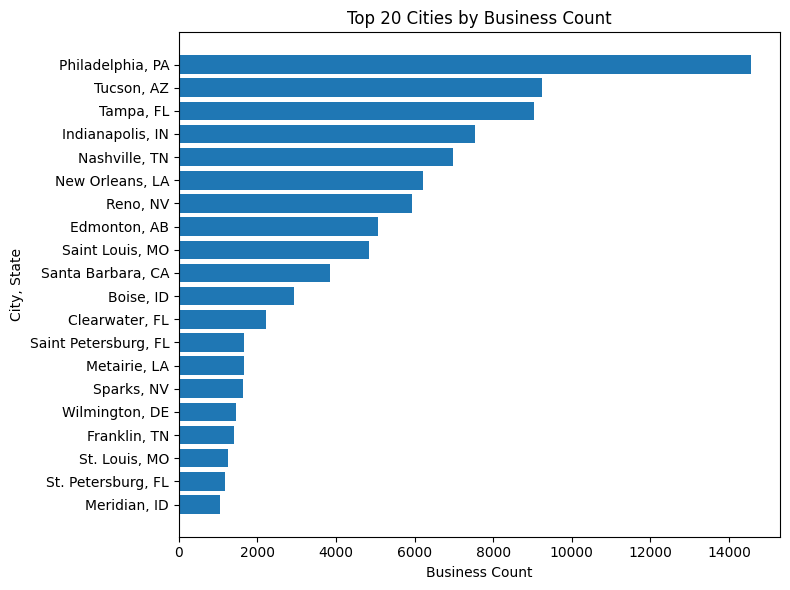

In [ ]:
import matplotlib.pyplot as plt

print("\n--------- CHART 02: Top 20 Cities by Business Count ---------")

top_cities_B = (df_B7.groupBy("city","state")
                .agg(F.countDistinct("business_id").alias("business_count"))
                .orderBy(F.desc("business_count"))
                .limit(20))

print("\nSupporting Frequency Table (Top 20 Cities)")
top_cities_B.show(truncate=False)

top_cities_pd = top_cities_B.toPandas()
top_cities_pd["city_state"] = top_cities_pd["city"] + ", " + top_cities_pd["state"]

plt.figure(figsize=(8,6))
plt.barh(top_cities_pd["city_state"][::-1], top_cities_pd["business_count"][::-1])
plt.xlabel("Business Count"); plt.ylabel("City, State")
plt.title("Top 20 Cities by Business Count")
plt.tight_layout(); plt.show()


### Chart 03 - Scatter: Stars vs Review Count


---------- CHART 03: Stars vs Review Count ----------

Descriptive Measures: Stars (exact mode)
+---+---+------------------+------+---+----------+----------+------+---+---+-----+-------------------+-----------------+--------+------------------+
|IQR|max|mean              |median|min|mode_count|mode_exact|n     |q1 |q3 |range|skewness           |stddev           |variable|variance          |
+---+---+------------------+------+---+----------+----------+------+---+---+-----+-------------------+-----------------+--------+------------------+
|1.5|5.0|3.5967235576603303|3.5   |1.0|31125     |4.0       |150346|3.0|4.5|4.0  |-0.5371260056579308|0.974420750920136|stars   |0.9494957998237619|
+---+---+------------------+------+---+----------+----------+------+---+---+-----+-------------------+-----------------+--------+------------------+


Descriptive Measures: Review Count (binned mode, bin=10)
+----+----+------------------+------+---+-----------------+----------+------+---+----+-----+-------

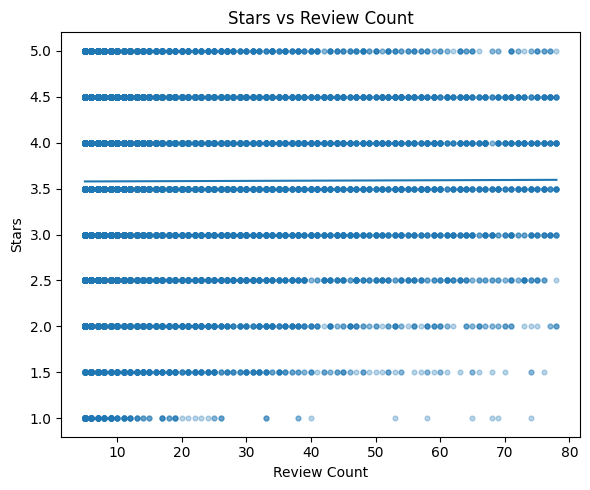

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("\n---------- CHART 03: Stars vs Review Count ----------")

print("\nDescriptive Measures: Stars (exact mode)")
numeric_desc_table(df_B7, "stars", mode_bin=None).show(truncate=False)

print("\nDescriptive Measures: Review Count (binned mode, bin=10)")
numeric_desc_table(df_B7, "review_count", mode_bin=10).show(truncate=False)

print("\nRelationship Measures (Stars vs Review Count)")
df_B7.agg(
    F.corr("review_count", "stars").alias("corr_reviewcount_stars"),
    F.covar_pop("review_count", "stars").alias("cov_reviewcount_stars")
).show(truncate=False)

scatter_pd = (df_B7
    .select("stars","review_count","review_count_outlier_flag")
    .where(F.col("stars").isNotNull() & F.col("review_count").isNotNull())
    .where((F.col("review_count_outlier_flag").isNull()) | (F.col("review_count_outlier_flag") == 0))
    .sample(False, 0.15, seed=15)
    .limit(60000)
    .toPandas()
)

plt.figure(figsize=(6,5))
plt.scatter(scatter_pd["review_count"], scatter_pd["stars"], alpha=0.30, s=12)

# Trendline (linear)
x = scatter_pd["review_count"].values
y = scatter_pd["stars"].values
m, b = np.polyfit(x, y, 1)
xs = np.array([np.nanmin(x), np.nanmax(x)])
plt.plot(xs, m*xs + b)

plt.xlabel("Review Count"); plt.ylabel("Stars")
plt.title("Stars vs Review Count")
plt.tight_layout(); plt.show()


### Chart 04 - Histogram: Stars Distribution


---------- CHART 04: Stars Distribution ----------

Descriptive Measures: Stars (exact mode)
+---+---+------------------+------+---+----------+----------+------+---+---+-----+-------------------+-----------------+--------+------------------+
|IQR|max|mean              |median|min|mode_count|mode_exact|n     |q1 |q3 |range|skewness           |stddev           |variable|variance          |
+---+---+------------------+------+---+----------+----------+------+---+---+-----+-------------------+-----------------+--------+------------------+
|1.5|5.0|3.5967235576603303|3.5   |1.0|31125     |4.0       |150346|3.0|4.5|4.0  |-0.5371260056579308|0.974420750920136|stars   |0.9494957998237619|
+---+---+------------------+------+---+----------+----------+------+---+---+-----+-------------------+-----------------+--------+------------------+



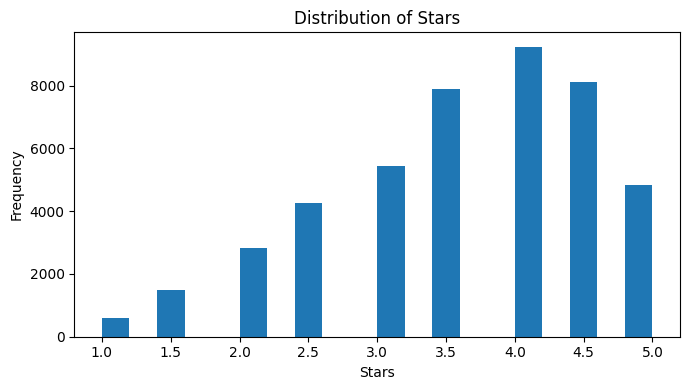

In [ ]:
import matplotlib.pyplot as plt

print("\n---------- CHART 04: Stars Distribution ----------")

print("\nDescriptive Measures: Stars (exact mode)")
numeric_desc_table(df_B7, "stars", mode_bin=None).show(truncate=False)

stars_pd = (df_B7.select("stars")
            .where(F.col("stars").isNotNull())
            .sample(False, 0.30, seed=15)
            .limit(500000)
            .toPandas())

plt.figure(figsize=(7,4))
plt.hist(stars_pd["stars"].dropna(), bins=20)
plt.xlabel("Stars"); plt.ylabel("Frequency")
plt.title("Distribution of Stars")
plt.tight_layout(); plt.show()


###Chart 05 - Top 20 Categories by Business Count


---------- CHART 05: Top 20 Categories by Business Count ----------

Supporting Frequency Table (Top 20 Categories)
+-------------------------+--------------+
|primary_category         |business_count|
+-------------------------+--------------+
|Restaurants              |15290         |
|Food                     |6783          |
|Shopping                 |5480          |
|Beauty & Spas            |4385          |
|Home Services            |3793          |
|Automotive               |3449          |
|Health & Medical         |3058          |
|Local Services           |2642          |
|Nightlife                |2291          |
|Event Planning & Services|2067          |
|Pizza                    |2066          |
|Bars                     |1935          |
|Active Life              |1919          |
|Sandwiches               |1721          |
|American (Traditional)   |1635          |
|Hotels & Travel          |1596          |
|Coffee & Tea             |1550          |
|Auto Repair           

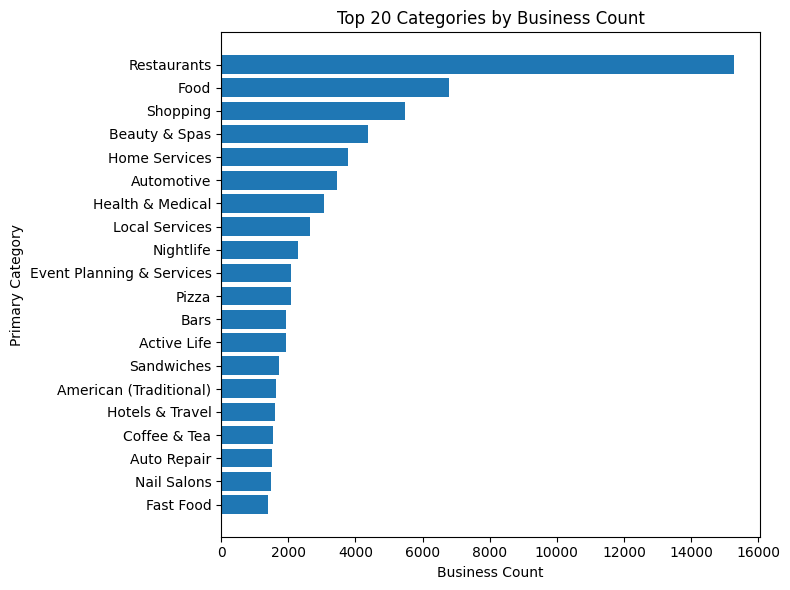

In [ ]:
import matplotlib.pyplot as plt

print("\n---------- CHART 05: Top 20 Categories by Business Count ----------")

top_categories_B = (df_B7.where(F.col("primary_category").isNotNull() & (F.length("primary_category") > 0))
                    .groupBy("primary_category")
                    .agg(F.countDistinct("business_id").alias("business_count"))
                    .orderBy(F.desc("business_count"))
                    .limit(20))

print("\nSupporting Frequency Table (Top 20 Categories)")
top_categories_B.show(truncate=False)

top_cat_pd = top_categories_B.toPandas()

plt.figure(figsize=(8,6))
plt.barh(top_cat_pd["primary_category"][::-1], top_cat_pd["business_count"][::-1])
plt.xlabel("Business Count"); plt.ylabel("Primary Category")
plt.title("Top 20 Categories by Business Count")
plt.tight_layout(); plt.show()


#Descriptive Analysis for Dashboard 03

##KPI Table

In [ ]:
from pyspark.sql import functions as F

print("\n----------- Dashboard KPIs ------------\n")

dfB = df_B7

# KPI 1: % High-rated businesses (stars >= 4.0)
kpi_high_rated = (dfB
    .where(F.col("stars").isNotNull())
    .agg(F.avg(F.when(F.col("stars") >= 4.0, 1).otherwise(0)).alias("pct_high"))
    .collect()[0]["pct_high"]
)

# KPI 2: % Low-rated businesses (stars < 3.0)
kpi_low_rated = (dfB
    .where(F.col("stars").isNotNull())
    .agg(F.avg(F.when(F.col("stars") < 3.0, 1).otherwise(0)).alias("pct_low"))
    .collect()[0]["pct_low"]
)

kpi_business = spark.createDataFrame([
    ("% High-rated (stars ≥ 4.0)", float(kpi_high_rated) if kpi_high_rated is not None else None),
    ("% Low-rated (stars < 3.0)", float(kpi_low_rated) if kpi_low_rated is not None else None),
], ["KPI", "Value"])

kpi_business.show(truncate=False)



----------- Dashboard KPIs ------------

+--------------------------+-------------------+
|KPI                       |Value              |
+--------------------------+-------------------+
|% High-rated (stars ≥ 4.0)|0.4962752584039482 |
|% Low-rated (stars < 3.0) |0.20460138613597967|
+--------------------------+-------------------+



## Chart 04- Bar: Open Rate by Primary Category (Top 10)


---------- CHART 04: Open Rate by Primary Category (Top 10) ----------

Supporting Table: Top 10 categories by business count
+-------------------------+--------------+
|primary_category         |business_count|
+-------------------------+--------------+
|Restaurants              |15290         |
|Food                     |6783          |
|Shopping                 |5480          |
|Beauty & Spas            |4385          |
|Home Services            |3793          |
|Automotive               |3449          |
|Health & Medical         |3058          |
|Local Services           |2642          |
|Nightlife                |2291          |
|Event Planning & Services|2067          |
+-------------------------+--------------+


Supporting Table: Open rate by category
+-------------------------+--------------+------------------+
|primary_category         |business_count|open_rate         |
+-------------------------+--------------+------------------+
|Restaurants              |15290         |0

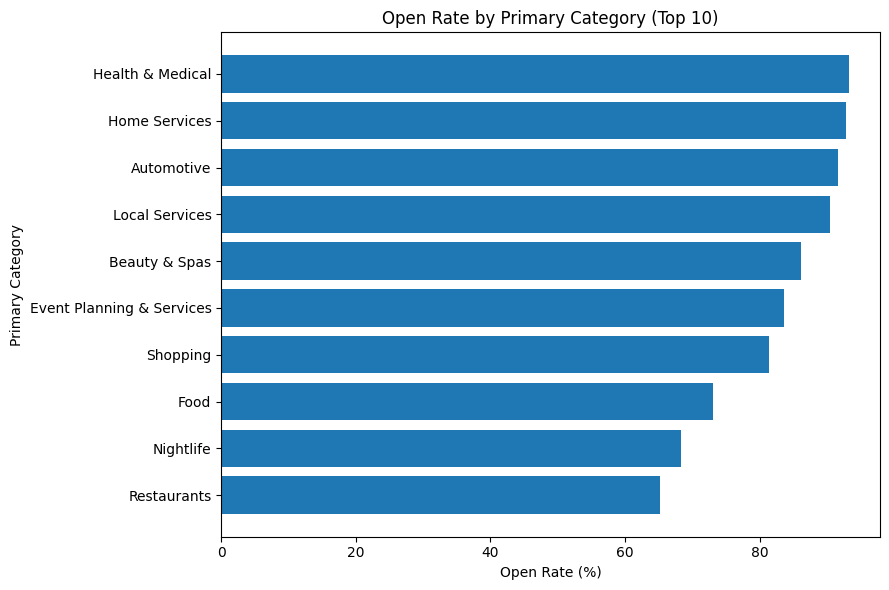

In [10]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

print("\n---------- CHART 04: Open Rate by Primary Category (Top 10) ----------")

df_cat = (df_B7
    .where(F.col("primary_category").isNotNull() & (F.length("primary_category") > 0))
    .select("business_id", "primary_category", F.col("is_open").cast("int").alias("is_open"))
    .dropna(subset=["business_id","primary_category","is_open"])
)

# Supporting table: Top 10 categories by business count
df_top10_cat = (df_cat
    .groupBy("primary_category")
    .agg(F.countDistinct("business_id").alias("business_count"))
    .orderBy(F.desc("business_count"))
    .limit(10)
)
print("\nSupporting Table: Top 10 categories by business count")
df_top10_cat.show(truncate=False)

top10_list = [r["primary_category"] for r in df_top10_cat.collect()]

# Open rate by category (Top 10)
df_open_rate = (df_cat
    .where(F.col("primary_category").isin(top10_list))
    .groupBy("primary_category")
    .agg(
        F.countDistinct("business_id").alias("business_count"),
        F.avg("is_open").alias("open_rate")   # 0..1
    )
    .orderBy(F.desc("business_count"))
)

print("\nSupporting Table: Open rate by category")
df_open_rate.show(truncate=False)

print("\nDescriptive Measures: open_rate")
numeric_desc_table(df_open_rate.where(F.col("open_rate").isNotNull()), "open_rate").show(truncate=False)

# Plot
pdf_open = df_open_rate.toPandas().sort_values("open_rate", ascending=True)

plt.figure(figsize=(9,6))
plt.barh(pdf_open["primary_category"], pdf_open["open_rate"] * 100.0)
plt.xlabel("Open Rate (%)")
plt.ylabel("Primary Category")
plt.title("Open Rate by Primary Category (Top 10)")
plt.tight_layout()
plt.show()


##Chart 05 - Bar: Avg Stars by Primary Category (Top 10)


---------- CHART 05: Avg Stars by Primary Category (Top 10) ----------

Supporting Table: Avg stars by category
+-------------------------+--------------+------------------+
|primary_category         |business_count|avg_stars         |
+-------------------------+--------------+------------------+
|Restaurants              |15290         |3.464780902550687 |
|Food                     |6783          |3.6679197994987467|
|Shopping                 |5480          |3.591058394160584 |
|Beauty & Spas            |4385          |3.764310148232611 |
|Home Services            |3793          |3.4360664381755868|
|Automotive               |3449          |3.4940562481878805|
|Health & Medical         |3058          |3.5727599738391107|
|Local Services           |2642          |3.634557153671461 |
|Nightlife                |2291          |3.6281099956350937|
|Event Planning & Services|2067          |3.5457184325108853|
+-------------------------+--------------+------------------+


Descriptive Measu

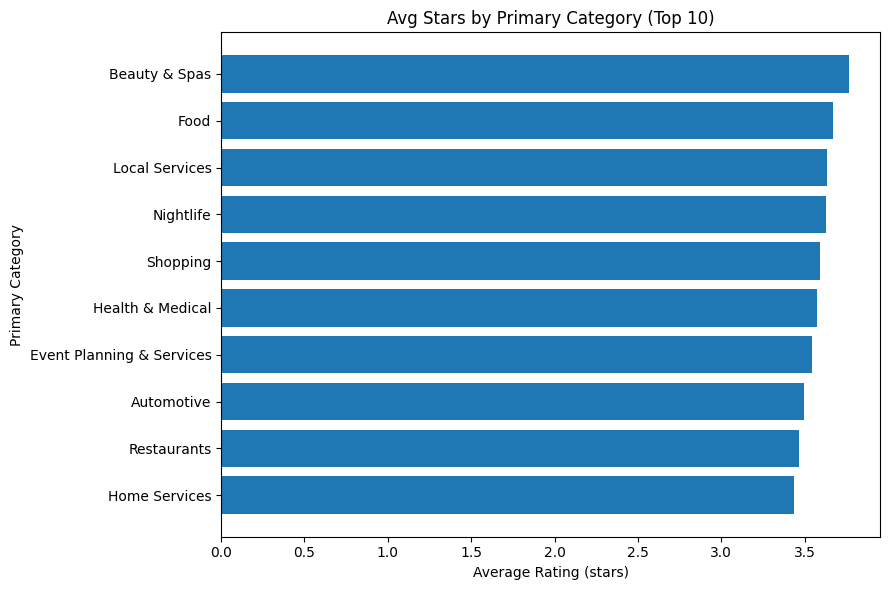

In [11]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

print("\n---------- CHART 05: Avg Stars by Primary Category (Top 10) ----------")

df_st = (df_B7
    .where(F.col("primary_category").isNotNull() & (F.length("primary_category") > 0) & F.col("stars").isNotNull())
    .select("business_id","primary_category",F.col("stars").cast("double").alias("stars"))
)

# Use same Top 10 categories (consistent with chart 01)
top10_list = [r["primary_category"] for r in (df_B7
    .where(F.col("primary_category").isNotNull() & (F.length("primary_category") > 0))
    .groupBy("primary_category")
    .agg(F.countDistinct("business_id").alias("business_count"))
    .orderBy(F.desc("business_count"))
    .limit(10)
).collect()]

df_avg = (df_st
    .where(F.col("primary_category").isin(top10_list))
    .groupBy("primary_category")
    .agg(
        F.countDistinct("business_id").alias("business_count"),
        F.avg("stars").alias("avg_stars")
    )
    .orderBy(F.desc("business_count"))
)

print("\nSupporting Table: Avg stars by category")
df_avg.show(truncate=False)

print("\nDescriptive Measures: avg_stars")
numeric_desc_table(df_avg.where(F.col("avg_stars").isNotNull()), "avg_stars").show(truncate=False)

# Plot
pdf_avg = df_avg.toPandas().sort_values("avg_stars", ascending=True)

plt.figure(figsize=(9,6))
plt.barh(pdf_avg["primary_category"], pdf_avg["avg_stars"])
plt.xlabel("Average Rating (stars)")
plt.ylabel("Primary Category")
plt.title("Avg Stars by Primary Category (Top 10)")
plt.tight_layout()
plt.show()


##Chart 06 - Boxplot: Stars Distribution by Open Status


---------- CHART 06: Stars Distribution by Open Status (Boxplot) ----------

Supporting Table: Count by is_open
+-------+------+
|is_open|count |
+-------+------+
|0      |30648 |
|1      |119698|
+-------+------+


Descriptive Measures: stars (overall)
+---+---+------------------+------+---+----------+----------+------+---+---+-----+-------------------+-----------------+--------+------------------+
|IQR|max|mean              |median|min|mode_count|mode_exact|n     |q1 |q3 |range|skewness           |stddev           |variable|variance          |
+---+---+------------------+------+---+----------+----------+------+---+---+-----+-------------------+-----------------+--------+------------------+
|1.5|5.0|3.5967235576603303|3.5   |1.0|31125     |4.0       |150346|3.0|4.5|4.0  |-0.5371260056579308|0.974420750920136|stars   |0.9494957998237619|
+---+---+------------------+------+---+----------+----------+------+---+---+-----+-------------------+-----------------+--------+------------------+


/tmp/ipython-input-143639719.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([closed, open_], labels=["Closed (0)", "Open (1)"], showfliers=True)


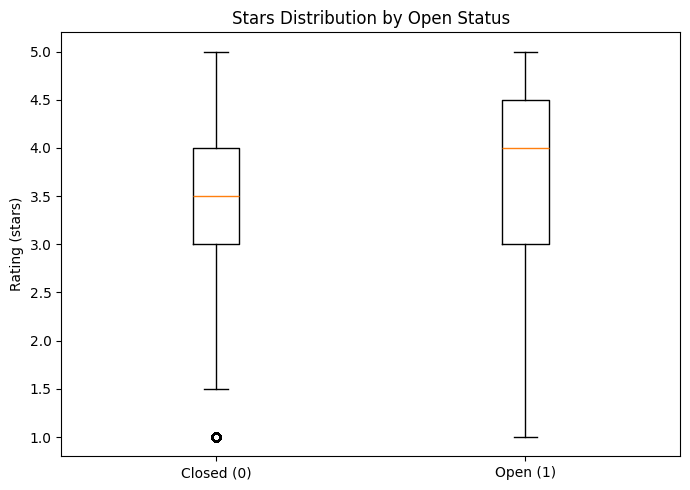

In [12]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

print("\n---------- CHART 06: Stars Distribution by Open Status (Boxplot) ----------")

df_box = (df_B7
    .where(F.col("stars").isNotNull() & F.col("is_open").isNotNull())
    .select(F.col("is_open").cast("int").alias("is_open"),
            F.col("stars").cast("double").alias("stars"))
)

print("\nSupporting Table: Count by is_open")
df_box.groupBy("is_open").count().orderBy("is_open").show(truncate=False)

print("\nDescriptive Measures: stars (overall)")
numeric_desc_table(df_box, "stars").show(truncate=False)

for v in [0, 1]:
    print(f"\nDescriptive Measures: stars where is_open={v}")
    numeric_desc_table(df_box.where(F.col("is_open")==v), "stars").show(truncate=False)

pdf_box = df_box.toPandas()
closed = pdf_box.loc[pdf_box["is_open"]==0, "stars"].dropna().values
open_  = pdf_box.loc[pdf_box["is_open"]==1, "stars"].dropna().values

plt.figure(figsize=(7,5))
plt.boxplot([closed, open_], labels=["Closed (0)", "Open (1)"], showfliers=True)
plt.ylabel("Rating (stars)")
plt.title("Stars Distribution by Open Status")
plt.tight_layout()
plt.show()
